In [31]:
# Prophet Forecasting
# Model trend, weekly/yearly seasonality and UK holiday effects; produce `yhat`, `yhat_lower`, and `yhat_upper` for evaluation and dashboard confidence.

from pathlib import Path
import itertools
import json
import logging
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from functools import partial

from ml.models.evaluation import chronological_split, evaluate_regression
from ml.models.prophet_model import fit_prophet_model, predict_prophet, tune_prophet
from prophet.plot import plot_components_plotly

logging.getLogger('cmdstanpy').setLevel(logging.ERROR)
sns.set_theme(style='whitegrid')

In [32]:
# Load the same target period
# Using the feature dataset—not the longer raw daily file—keeps Prophet's evaluation dates identical to the other models.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
FEATURE_PATH = PROJECT_ROOT / 'data' / 'features' / 'sales_time_features.csv'
MODEL_DIR = PROJECT_ROOT / 'artifacts' / 'models'
REPORT_DIR = PROJECT_ROOT / 'artifacts' / 'reports'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

source = pd.read_csv(FEATURE_PATH, parse_dates=['date']).sort_values('date').reset_index(drop=True)
prophet_df = source[['date', 'net_revenue']].rename(columns={'date':'ds', 'net_revenue':'y'})
assert prophet_df['ds'].is_unique and prophet_df['ds'].is_monotonic_increasing
assert prophet_df[['ds','y']].notna().all().all()
assert np.isfinite(prophet_df['y']).all()
print(prophet_df.shape, prophet_df.ds.min(), prophet_df.ds.max())
prophet_df.head()

(649, 2) 2010-03-01 00:00:00 2011-12-09 00:00:00


,ds,y
0,2010-03-01,25339.94
1,2010-03-02,25637.71
2,2010-03-03,33833.59
3,2010-03-04,31540.73
4,2010-03-05,27536.73


In [33]:
# Reuse the shared chronological 70/15/15 split on Prophet's ds/y columns.
split = chronological_split(
    prophet_df,
    date_column='ds',
    train_fraction=0.70,
    validation_fraction=0.15,
)
train_df = split.train
validation_df = split.validation
test_df = split.test
assert train_df.ds.max() < validation_df.ds.min() < test_df.ds.min()
split.summary(date_column='ds')

,split,rows,start,end
0,train,454,2010-03-01,2011-05-28
1,validation,97,2011-05-29,2011-09-02
2,test,98,2011-09-03,2011-12-09


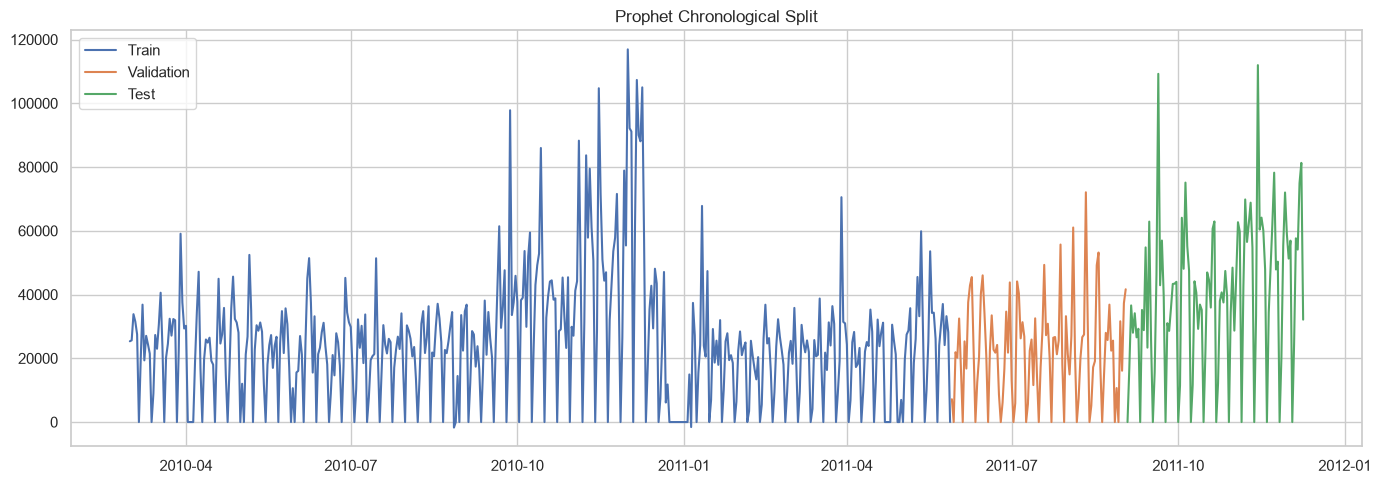

In [34]:
plt.figure(figsize=(14,5))
plt.plot(train_df.ds, train_df.y, label='Train')
plt.plot(validation_df.ds, validation_df.y, label='Validation')
plt.plot(test_df.ds, test_df.y, label='Test')
plt.title('Prophet Chronological Split'); plt.legend(); plt.tight_layout(); plt.show()

In [35]:
# Reuse the shared regression metrics while fixing this notebook's model label.
evaluate = partial(evaluate_regression, 'Prophet')

In [36]:
# Reuse the model factory configured with weekly/yearly seasonality and GB holidays.
from ml.models.prophet_model import build_prophet_model as build_prophet

In [37]:
# Tune only on the training period; each fold fits on past dates and predicts a later block.
parameter_grid = [
    {
        'changepoint_prior_scale': changepoint,
        'seasonality_prior_scale': seasonality,
        'holidays_prior_scale': holidays,
        'seasonality_mode': mode,
    }
    for changepoint, seasonality, holidays, mode in itertools.product(
        [0.01, 0.05],
        [1.0, 10.0],
        [1.0, 10.0],
        ['additive', 'multiplicative'],
    )
]
started = time.perf_counter()
cv_results = tune_prophet(
    train_df,
    parameter_grid,
    date_column='ds',
    target_column='y',
    n_splits=3,
    country_holidays='GB',
    interval_width=0.80,
    uncertainty_samples=1000,
)
print('Seconds:', round(time.perf_counter() - started, 1))
cv_results.head(10)

Seconds: 8.9


,changepoint_prior_scale,seasonality_prior_scale,holidays_prior_scale,seasonality_mode,mean_cv_RMSE,std_cv_RMSE
0,0.01,1.0,1.0,additive,24557.399815,18050.731251
1,0.01,1.0,10.0,additive,24557.673707,18041.476625
2,0.01,10.0,1.0,additive,24601.685507,18128.916608
3,0.01,10.0,10.0,additive,24619.613863,18152.025597
4,0.01,1.0,10.0,multiplicative,24892.061300,13716.350731
5,0.01,10.0,1.0,multiplicative,24972.635440,13958.968124
6,0.01,10.0,10.0,multiplicative,25059.079474,13926.719264
7,0.01,1.0,1.0,multiplicative,25084.848409,13882.700183
8,0.05,1.0,10.0,additive,28046.660734,20920.808324
9,0.05,10.0,10.0,additive,28064.921720,20862.229826


In [38]:
# Fit the selected configuration on train only, then score the untouched validation period.
parameter_names = [
    'changepoint_prior_scale',
    'seasonality_prior_scale',
    'holidays_prior_scale',
    'seasonality_mode',
]
best_params = {name: cv_results.iloc[0][name] for name in parameter_names}
validation_model = fit_prophet_model(
    train_df,
    best_params,
    date_column='ds',
    target_column='y',
    country_holidays='GB',
    interval_width=0.80,
    uncertainty_samples=1000,
)
validation_forecast = predict_prophet(validation_model, validation_df['ds'])
validation_predictions = validation_df.merge(
    validation_forecast,
    on='ds',
    how='left',
)
prophet_validation_metrics = pd.DataFrame([
    evaluate('validation', validation_predictions.y, validation_predictions.yhat)
])
display(best_params)
display(prophet_validation_metrics.round(3))

{'changepoint_prior_scale': np.float64(0.01),
 'seasonality_prior_scale': np.float64(1.0),
 'holidays_prior_scale': np.float64(1.0),
 'seasonality_mode': 'additive'}

,model,split,MAE,RMSE,MAPE_pct,R2
0,Prophet,validation,8096.652,10787.23,39.758,0.511


In [39]:
# Refit on train + validation and evaluate the held-out test dates once.
development_df = pd.concat([train_df, validation_df], ignore_index=True)
final_prophet = fit_prophet_model(
    development_df,
    best_params,
    date_column='ds',
    target_column='y',
    country_holidays='GB',
    interval_width=0.80,
    uncertainty_samples=1000,
)
test_forecast = predict_prophet(
    final_prophet,
    test_df['ds'],
    components=['trend', 'weekly', 'yearly'],
)
prophet_test_predictions = test_df.merge(
    test_forecast,
    on='ds',
    how='left',
)
prophet_test_metrics = pd.DataFrame([
    evaluate('test', prophet_test_predictions.y, prophet_test_predictions.yhat)
])
prophet_test_metrics.round(3)

,model,split,MAE,RMSE,MAPE_pct,R2
0,Prophet,test,12334.488,16838.063,29.921,0.503


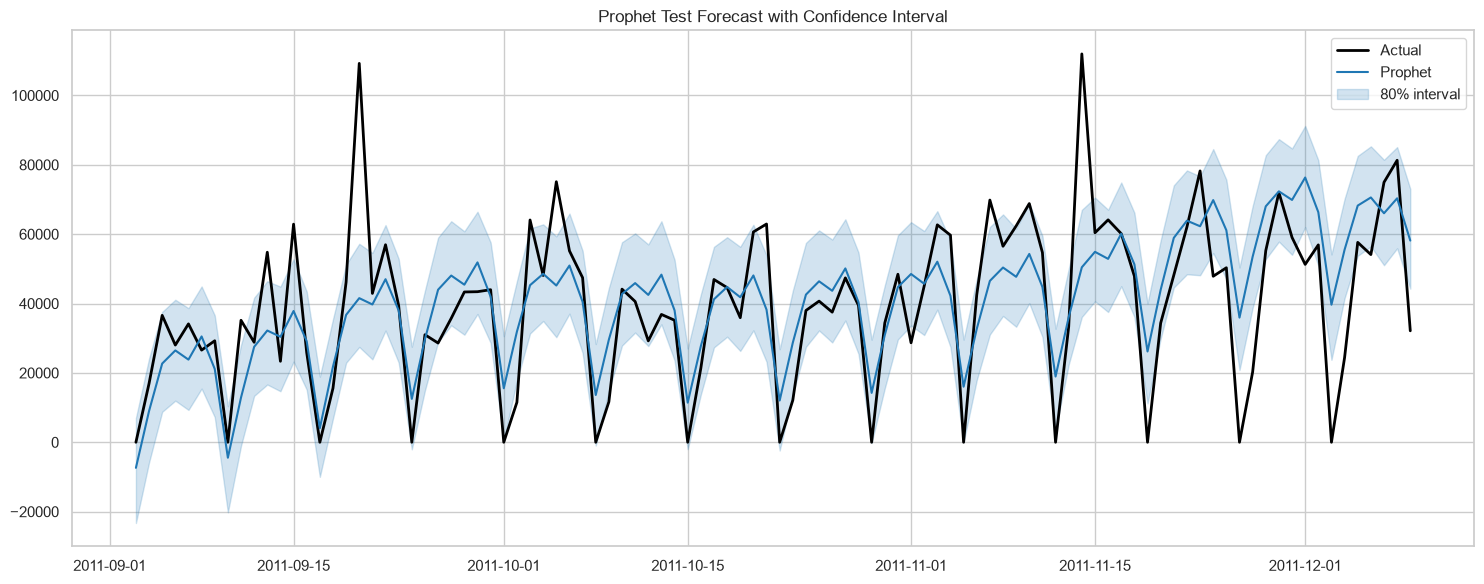

Coverage %: 71.43 | Average width: 29436.4


In [40]:
# Forecast plot and confidence interval
plt.figure(figsize=(15,6))
plt.plot(prophet_test_predictions.ds,prophet_test_predictions.y,label='Actual',color='black',linewidth=2)
plt.plot(prophet_test_predictions.ds,prophet_test_predictions.yhat,label='Prophet',color='tab:blue')
plt.fill_between(prophet_test_predictions.ds,prophet_test_predictions.yhat_lower,prophet_test_predictions.yhat_upper,color='tab:blue',alpha=.2,label='80% interval')
plt.title('Prophet Test Forecast with Confidence Interval'); plt.legend(); plt.tight_layout(); plt.show()
coverage = ((prophet_test_predictions.y>=prophet_test_predictions.yhat_lower)&(prophet_test_predictions.y<=prophet_test_predictions.yhat_upper)).mean()*100
avg_width = (prophet_test_predictions.yhat_upper-prophet_test_predictions.yhat_lower).mean()
print('Coverage %:',round(coverage,2),'| Average width:',round(avg_width,2))

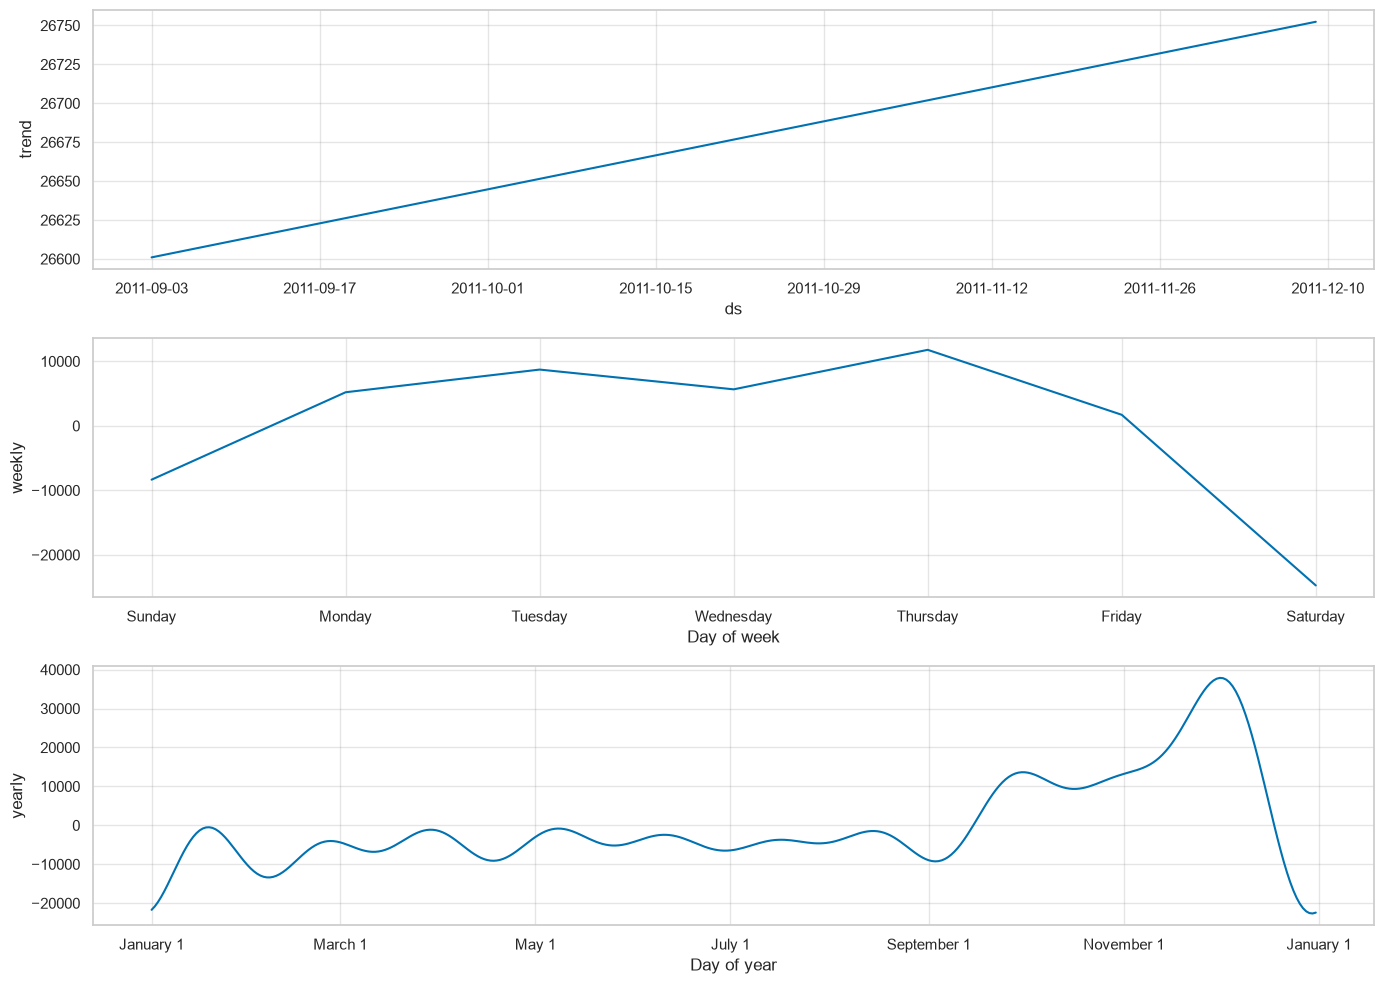

In [41]:
# Inspect trend, weekly, yearly and holiday components
# Yearly seasonality is based on less than two full years of observations, so interpret it cautiously. Holiday effects are useful only if the selected country matches the business calendar.
component_figure = final_prophet.plot_components(test_forecast, uncertainty=False)
component_figure.set_size_inches(14,10)
plt.tight_layout(); plt.show()

In [42]:
# Refit on all history and create a 90-day dashboard forecast
production_prophet = build_prophet(best_params)
production_prophet.fit(prophet_df)
future = production_prophet.make_future_dataframe(periods=90,freq='D',include_history=False)
future_forecast = production_prophet.predict(future)
prophet_future_90d = future_forecast[['ds','yhat','yhat_lower','yhat_upper','trend','weekly','yearly']].copy()
prophet_future_90d['horizon_day'] = np.arange(1,len(prophet_future_90d)+1)
prophet_future_90d.head()

,ds,yhat,yhat_lower,yhat_upper,trend,weekly,yearly,horizon_day
0,2011-12-10,21368.703081,4911.522704,36161.072798,25922.369050,-27009.390128,22455.724159,1
1,2011-12-11,36951.591590,22042.533882,53036.575938,25921.720998,-9328.256170,20358.126762,2
2,2011-12-12,50352.918453,34982.349772,66050.136576,25921.072945,6378.144929,18053.700579,3
3,2011-12-13,50848.157894,35393.045782,67697.263666,25920.424893,9361.700624,15566.032377,4
4,2011-12-14,45206.108618,29551.503049,61446.600585,25919.776840,6363.249728,12923.082050,5


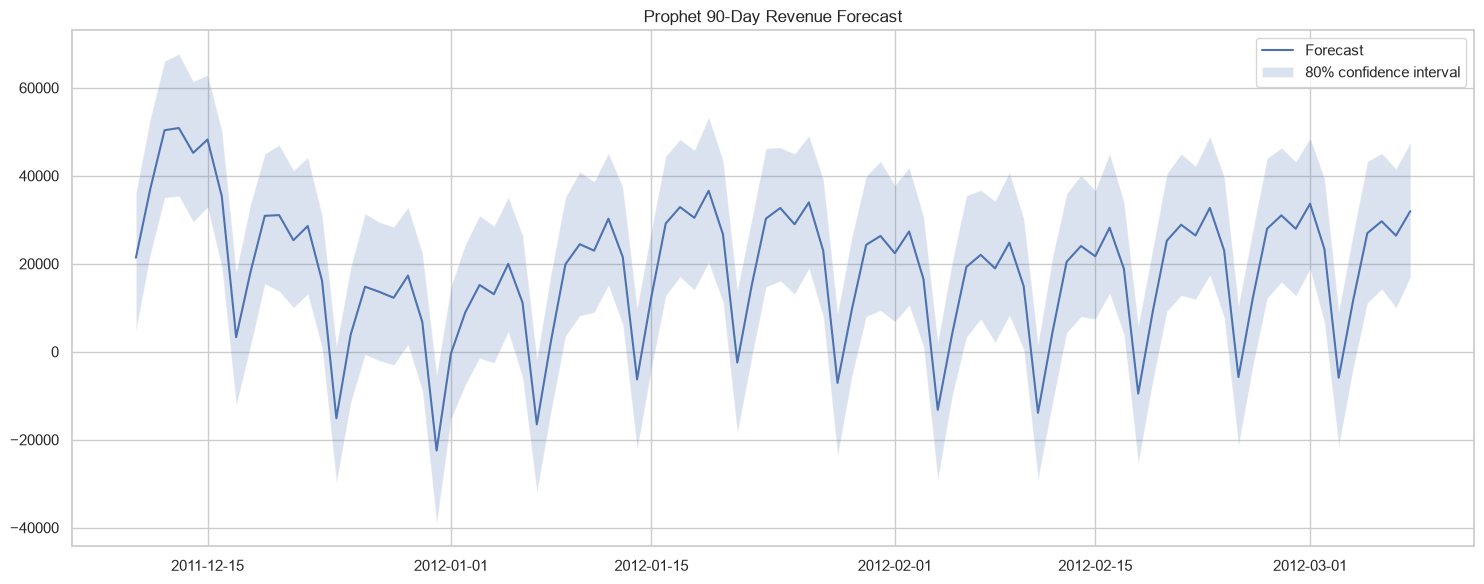

In [43]:
plt.figure(figsize=(15,6))
plt.plot(prophet_future_90d.ds,prophet_future_90d.yhat,label='Forecast')
plt.fill_between(prophet_future_90d.ds,prophet_future_90d.yhat_lower,prophet_future_90d.yhat_upper,alpha=.2,label='80% confidence interval')
plt.title('Prophet 90-Day Revenue Forecast'); plt.legend(); plt.tight_layout(); plt.show()

In [44]:
# Save model
joblib.dump(production_prophet,MODEL_DIR/'prophet_final.joblib')
prophet_validation_metrics.to_csv(REPORT_DIR/'prophet_validation_metrics.csv',index=False)
prophet_test_metrics.to_csv(REPORT_DIR/'prophet_test_metrics.csv',index=False)
prophet_test_predictions.to_csv(REPORT_DIR/'prophet_test_predictions.csv',index=False)
prophet_future_90d.to_csv(REPORT_DIR/'prophet_future_90d.csv',index=False)
cv_results.to_csv(REPORT_DIR/'prophet_cv_results.csv',index=False)
metadata = {
    'model':'Prophet',
    'country_holidays':'GB',
    'interval_width':.80,
    'best_parameters':
        {
            k:(float(v) 
               if isinstance(v,(np.floating,np.integer)) 
               else 
                v
                ) 
            for k,v in best_params.items()
        },
        'validation_end':str(validation_df.ds.max().date()),
        'test_end':str(test_df.ds.max().date()),
        'test_interval_coverage_pct':float(coverage),
        'test_average_interval_width':float(avg_width)
    }
(REPORT_DIR/'prophet_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
print('completed successfully.')

completed successfully.


## Completion criteria

Prophet was tuned only on training folds; 
validation and test dates match; 
test contains actual, `yhat`, `yhat_lower`, and `yhat_upper`; 
interval coverage is reported.